# BRFSS 2024: KA1 Milestone 2
**Ngozichukwuka Ejiofor | ANLY 530**

Research question: Can eleven respondent characteristics classify concurrent frequent mental distress, and does a constrained decision tree improve on regularized logistic regression in states excluded from training?

This notebook extends Milestone 1 into model execution. This is methodological research, not a diagnostic or causal study.

## 1. Analysis settings
Using all eligible respondents for the main results. The smaller sample is only for checking that the code works, and its survey weights have not been adjusted for population estimates. Keeping the random seed at 42 so the analysis can be repeated consistently. 

In [24]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

OUTPUT_DIR=Path('milestone2_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
DIAGNOSTIC_N=None  # Keep None for the main BRFSS analysis; 20000 is debugging only.
RUN_STABILITY=True
RUN_SENSITIVITIES=True  # Set True for nested no-physical-health and unweighted-fitting checks.


## 2. Reusable analysis functions
The next cell defines the implementation. Run it once; it does not load data or fit a model by itself. Numeric variables use median imputation and standardization; categorical variables use mode imputation and indicator encoding, all learned inside the relevant training fold. Scaling is unnecessary for tree splits but is retained in the shared preparation pipeline. Preprocessing is unweighted; fitting weights are normalized to mean one separately for each fit. Survey weights are used in evaluation.

**Outcome:** 14–30 mentally unhealthy days versus 0–13. The response code for zero days becomes zero; unknown, refused, invalid, or missing outcomes are excluded. Routine-checkup code 8 is a valid “never” response. Survey design fields and all target-derived fields are excluded from predictors.

In [25]:
"""BRFSS Milestone 2. Exports aggregate results only. No bundled respondent data."""
from pathlib import Path
import hashlib, json, os, platform, warnings
import numpy as np
import pandas as pd
import scipy
from scipy.special import expit, logit
from scipy.optimize import minimize
from scipy.stats import t as student_t
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve)

SEED=42
NUMERIC=['_AGE80','_BMI5','PHYSHLTH']
CATEGORICAL=['SEXVAR','EDUCA','INCOME3','EMPLOY1','CHECKUP1','_TOTINDA','_SMOKER3','DIFFWALK']
FEATURES=NUMERIC+CATEGORICAL
LABELS=dict(zip(FEATURES,['Age','Body mass index','Physically unhealthy days','Recorded sex',
    'Education','Household income','Employment','Routine-checkup history',
    'Leisure-time physical activity','Smoking status','Walking difficulty']))
VALID={'_AGE80':range(18,81),'SEXVAR':[1,2],'EDUCA':range(1,7),'INCOME3':range(1,12),
       'EMPLOY1':range(1,9),'CHECKUP1':[1,2,3,4,8],'_TOTINDA':[1,2],
       '_SMOKER3':[1,2,3,4],'DIFFWALK':[1,2]}
GRIDS={'Logistic regression':[{'C':x} for x in [.1,1,10]],
       'Decision tree':[{'max_depth':d,'min_samples_leaf':l} for d in [3,6] for l in [200,50]]}
BASELINE='Constant training prevalence'
MAC_PATH=Path('/Users/honeydrops/Library/Mobile Documents/com~apple~CloudDocs/Documents/Harrisburg University/Classes/Fall 2026/ANLY 530/Project/brfss-mental-distress-ka1/LLCP2024.XPT')


def resolve_path():
    explicit=os.environ.get('BRFSS_PATH')
    if explicit:
        path=Path(explicit).expanduser()
        if not path.is_file(): raise FileNotFoundError('BRFSS_PATH does not point to a local file.')
        return path
    for path in [Path('LLCP2024.XPT'),Path('data/LLCP2024.XPT'),Path('../LLCP2024.XPT'),Path('../data/LLCP2024.XPT'),MAC_PATH]:
        if path.is_file(): return path
    raise FileNotFoundError('Download LLCP2024.XPT locally; set BRFSS_PATH or place it beside the notebook. Do not upload it to GitHub.')


def prepare(raw):
    required=FEATURES+['MENTHLTH','_STATE','_LLCPWT']
    absent=sorted(set(required)-set(raw.columns))
    if absent: raise ValueError(f'Missing required columns: {absent}; check the release/codebook.')
    d=raw[required+[x for x in ['_PSU','_STSTR'] if x in raw]].copy().reset_index(drop=True)
    for c in d: d[c]=pd.to_numeric(d[c],errors='coerce')
    days=d.MENTHLTH.replace(88,0)
    d['target']=np.where(days.between(0,30),days.ge(14).astype(float),np.nan)
    for c,valid in VALID.items(): d[c]=d[c].where(d[c].isin(valid))
    d['_BMI5']=d['_BMI5'].where(np.isfinite(d['_BMI5']) & d['_BMI5'].gt(0))/100
    d['PHYSHLTH']=d.PHYSHLTH.replace(88,0).where(lambda s:s.between(0,30))
    good=d.target.notna() & np.isfinite(d._LLCPWT) & d._LLCPWT.gt(0) & np.isfinite(d._STATE)
    flow=pd.DataFrame({'Stage':['Input','Valid outcome','Valid outcome and positive weight','Eligible with state'],
        'N':[len(d),int(d.target.notna().sum()),int((d.target.notna() & np.isfinite(d._LLCPWT) & d._LLCPWT.gt(0)).sum()),int(good.sum())]})
    missing=pd.DataFrame({'Predictor':[LABELS[c] for c in FEATURES],
        'Raw_missing_n':[raw[c].isna().sum() for c in FEATURES],
        'Recoded_missing_n':[d[c].isna().sum() for c in FEATURES],
        'Eligible_missing_pct':[100*d.loc[good,c].isna().mean() for c in FEATURES]})
    cohort=d.loc[good].drop(columns='MENTHLTH').copy()
    cohort['target']=cohort.target.astype(int)
    if len(cohort)==0 or cohort.target.nunique()!=2: raise ValueError('Eligible cohort must contain both classes.')
    return cohort,flow,missing


def splits(d,n=5,seed=42):
    if d._STATE.nunique()<n: raise ValueError('Too few states for grouped validation.')
    result=list(StratifiedGroupKFold(n_splits=n,shuffle=True,random_state=seed).split(d[FEATURES],d.target,d._STATE))
    for tr,te in result:
        assert set(d._STATE.iloc[tr]).isdisjoint(d._STATE.iloc[te])
        if d.target.iloc[tr].nunique()!=2 or d.target.iloc[te].nunique()!=2:
            raise ValueError('One-class split: inspect state coverage before modeling.')
    return result


def pipeline(name,params,features=FEATURES,seed=42):
    numeric=[c for c in NUMERIC if c in features]
    categorical=[c for c in CATEGORICAL if c in features]
    pre=ColumnTransformer([
      ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),('scale',StandardScaler())]),numeric),
      ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent',keep_empty_features=True)),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),categorical)],sparse_threshold=0)
    model=(LogisticRegression(max_iter=3000,random_state=seed,**params) if name=='Logistic regression'
        else DecisionTreeClassifier(random_state=seed,**params))
    return Pipeline([('prepare',pre),('model',model)])


def fit_model(name,params,d,features=FEATURES,weighted=True,seed=42):
    w=d._LLCPWT.to_numpy() if weighted else np.ones(len(d))
    return pipeline(name,params,features,seed).fit(d[features],d.target,model__sample_weight=w/w.mean())


def calibration(y,p,w):
    """Unpenalized weighted calibration intercept and slope, descriptive evaluation only."""
    if len(np.unique(y))<2 or np.std(p)<1e-10: return np.nan,np.nan
    x=logit(np.clip(p,1e-6,1-1e-6)); wn=w/w.sum()
    def objective(ab):
        eta=ab[0]+ab[1]*x
        return np.sum(wn*(np.logaddexp(0,eta)-y*eta))
    def gradient(ab):
        delta=wn*(expit(ab[0]+ab[1]*x)-y)
        return np.array([delta.sum(),np.dot(delta,x)])
    fit=minimize(objective,[0.,1.],jac=gradient,method='BFGS')
    return tuple(fit.x) if fit.success else (np.nan,np.nan)


def metrics(y,p,w,threshold=.5,include_calibration=False):
    y,p,w=np.asarray(y),np.asarray(p),np.asarray(w)
    tn,fp,fn,tp=confusion_matrix(y,p>=threshold,labels=[0,1],sample_weight=w).ravel()
    prevalence=np.average(y,weights=w)
    ap=average_precision_score(y,p,sample_weight=w) if np.any(y==1) else np.nan
    result={'N':len(y),'Positive_n':int(y.sum()),'Prevalence':prevalence,'AP':ap,
        'AP_prevalence_ratio':ap/prevalence if prevalence else np.nan,
        'ROC_AUC':roc_auc_score(y,p,sample_weight=w) if len(np.unique(y))==2 else np.nan,
        'Brier':brier_score_loss(y,p,sample_weight=w),
        'Sensitivity':tp/(tp+fn) if tp+fn else np.nan,
        'Specificity':tn/(tn+fp) if tn+fp else np.nan,
        'Precision':tp/(tp+fp) if tp+fp else np.nan,
        'TN_weighted':tn,'FP_weighted':fp,'FN_weighted':fn,'TP_weighted':tp}
    if include_calibration:
        result['Calibration_intercept'],result['Calibration_slope']=calibration(y,p,w)
    return result


def choose_threshold(y,p,w,target=.70):
    """Largest threshold reaching training OOF sensitivity target, including ties."""
    precision,recall,threshold=precision_recall_curve(y,p,sample_weight=w)
    candidates=threshold[recall[:-1]>=target]
    return float(candidates.max()) if len(candidates) else 0.


def case_mix(d):
    rows=[]
    for state,g in d.groupby('_STATE',sort=True):
        w=g._LLCPWT
        item={'State_code':int(state),'N':len(g),'Positive_n':int(g.target.sum()),
          'Weighted_prevalence':np.average(g.target,weights=w),
          'Age_18_44_fraction':np.average(g._AGE80.lt(45),weights=w),
          'Age_65_plus_fraction':np.average(g._AGE80.ge(65),weights=w),
          'Recorded_female_fraction':np.average(g.SEXVAR.eq(2),weights=w),
          'Income_missing_fraction':np.average(g.INCOME3.isna(),weights=w)}
        for c in NUMERIC:
            ok=g[c].notna()
            item[LABELS[c]+'_weighted_mean']=np.average(g.loc[ok,c],weights=w.loc[ok]) if ok.any() else np.nan
        rows.append(item)
    return pd.DataFrame(rows)


def nested_comparison(d,out,outer_folds=5,inner_folds=3,features=FEATURES,weighted_fit=True,seed=42):
    """Fits/tunes only within outer training states. Row-level predictions stay in memory."""
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    outer=splits(d,outer_folds,seed)
    predictions={name:np.full(len(d),np.nan) for name in [BASELINE]+list(GRIDS)}
    decisions={name:np.zeros(len(d),dtype=bool) for name in predictions}
    fold_ids=np.zeros(len(d),dtype=int)
    fold_rows=[];selection=[];tuning=[];state_rows=[];complexity=[];gaps=[];assignments=[];fitted_models={}
    for fold,(tr,te) in enumerate(outer,1):
        train,test=d.iloc[tr],d.iloc[te]
        fold_ids[te]=fold
        assignments.extend({'State_code':int(s),'Outer_fold':fold} for s in sorted(test._STATE.unique()))
        inner=splits(train,inner_folds,seed)
        baseline=float(np.average(train.target,weights=train._LLCPWT))
        candidate_predictions={BASELINE:(np.full(len(test),baseline),baseline)}
        for name,grid in GRIDS.items():
            print(f'Outer fold {fold}/{outer_folds}: tuning {name}',flush=True)
            best_score=-np.inf;best=None
            for params in grid:
                oof=np.full(len(train),np.nan);scores=[];train_scores=[]
                for it,iv in inner:
                    model=fit_model(name,params,train.iloc[it],features,weighted_fit,seed)
                    vp=model.predict_proba(train.iloc[iv][features])[:,1]
                    oof[iv]=vp
                    scores.append(average_precision_score(train.target.iloc[iv],vp,sample_weight=train._LLCPWT.iloc[iv]))
                    tp=model.predict_proba(train.iloc[it][features])[:,1]
                    train_scores.append(average_precision_score(train.target.iloc[it],tp,sample_weight=train._LLCPWT.iloc[it]))
                score=float(np.mean(scores))
                tuning.append({'Outer_fold':fold,'Model':name,'Parameters':json.dumps(params,sort_keys=True),
                    'Mean_inner_AP':score,'Mean_inner_training_AP':np.mean(train_scores),
                    'Inner_training_validation_AP_gap':np.mean(train_scores)-score})
                # First candidate wins exact ties; grids place stronger regularization first.
                if score>best_score+1e-12: best_score=score;best=(params,oof)
            params,inner_oof=best
            threshold=choose_threshold(train.target.to_numpy(),inner_oof,train._LLCPWT.to_numpy())
            selected=fit_model(name,params,train,features,weighted_fit,seed)
            fitted_models[(fold,name)]=selected
            p=selected.predict_proba(test[features])[:,1]
            candidate_predictions[name]=(p,threshold)
            selection.append({'Outer_fold':fold,'Model':name,'Parameters':json.dumps(params,sort_keys=True),
                'Mean_inner_AP':best_score,'Training_selected_threshold':threshold,
                'Inner_OOF_sensitivity':metrics(train.target,inner_oof,train._LLCPWT,threshold)['Sensitivity']})
            train_ap=average_precision_score(train.target,selected.predict_proba(train[features])[:,1],sample_weight=train._LLCPWT)
            outer_ap=average_precision_score(test.target,p,sample_weight=test._LLCPWT)
            gaps.append({'Outer_fold':fold,'Model':name,'Apparent_training_AP':train_ap,'Heldout_AP':outer_ap,'AP_gap':train_ap-outer_ap})
            core=selected['model']
            item={'Outer_fold':fold,'Model':name,'Encoded_predictors_n':len(selected['prepare'].get_feature_names_out())}
            if name=='Decision tree': item.update(Depth=core.get_depth(),Leaves=core.get_n_leaves(),Nodes=core.tree_.node_count)
            else: item.update(C=core.C,Coefficient_L2_norm=np.linalg.norm(core.coef_))
            complexity.append(item)
        for name,(p,threshold) in candidate_predictions.items():
            predictions[name][te]=p
            # Constant baseline uses the same training sensitivity rule: classify all positive at p.
            decisions[name][te]=(p>=threshold)
            for operating,t in [('Default 0.50',.5),('Training-selected sensitivity',threshold)]:
                fold_rows.append({'Outer_fold':fold,'Model':name,'Operating_point':operating,'Threshold':t,
                    **metrics(test.target,p,test._LLCPWT,t,True)})
            for state in sorted(test._STATE.unique()):
                mask=test._STATE.eq(state).to_numpy()
                state_rows.append({'Outer_fold':fold,'State_code':int(state),'Model':name,'Threshold':threshold,
                    **metrics(test.target.to_numpy()[mask],p[mask],test._LLCPWT.to_numpy()[mask],threshold)})
        pd.DataFrame(fold_rows).to_csv(out/'fold_metrics.csv',index=False)
    pooled=[];subgroups=[];bins=[]
    age=pd.cut(d._AGE80,[17,44,64,80],labels=['18–44','45–64','65+'])
    sex=d.SEXVAR.map({1:'Recorded male',2:'Recorded female'}).fillna('Missing recorded sex')
    for name,p in predictions.items():
        for op,decision in [('Default 0.50',p>=.5),('Training-selected sensitivity',decisions[name])]:
            m=metrics(d.target,p,d._LLCPWT,.5,True)
            # Fold-specific thresholds cannot be represented by one pooled scalar threshold.
            counts=confusion_matrix(d.target,decision,labels=[0,1],sample_weight=d._LLCPWT).ravel()
            tn,fp,fn,tp=counts
            m.update(Sensitivity=tp/(tp+fn),Specificity=tn/(tn+fp),Precision=tp/(tp+fp) if tp+fp else np.nan,
                     TN_weighted=tn,FP_weighted=fp,FN_weighted=fn,TP_weighted=tp)
            pooled.append({'Model':name,'Operating_point':op,**m})
        for kind,values in [('Recorded sex',sex),('Age group',age)]:
            for value in values.dropna().unique():
                mask=values.eq(value).to_numpy();yp=d.target.to_numpy()[mask];wp=d._LLCPWT.to_numpy()[mask]
                m=metrics(yp,p[mask],wp)
                tn,fp,fn,tp=confusion_matrix(yp,decisions[name][mask],labels=[0,1],sample_weight=wp).ravel()
                m.update(Sensitivity=tp/(tp+fn) if tp+fn else np.nan,Specificity=tn/(tn+fp) if tn+fp else np.nan,
                         Precision=tp/(tp+fp) if tp+fp else np.nan,
                         TN_weighted=tn,FP_weighted=fp,FN_weighted=fn,TP_weighted=tp)
                subgroups.append({'Model':name,'Group_type':kind,'Group':str(value),**m})
        b=np.minimum((p*10).astype(int),9)
        for k in np.unique(b):
            mask=b==k
            bins.append({'Model':name,'Probability_bin':int(k),'N':int(mask.sum()),
                'Mean_predicted_probability':np.average(p[mask],weights=d._LLCPWT.to_numpy()[mask]),
                'Observed_weighted_prevalence':np.average(d.target.to_numpy()[mask],weights=d._LLCPWT.to_numpy()[mask])})
    frames={'fold_metrics':pd.DataFrame(fold_rows),'pooled_metrics':pd.DataFrame(pooled),
        'selected_settings':pd.DataFrame(selection),'inner_complexity_comparison':pd.DataFrame(tuning),
        'training_heldout_gaps':pd.DataFrame(gaps),'model_complexity':pd.DataFrame(complexity),
        'state_metrics':pd.DataFrame(state_rows),'subgroup_metrics':pd.DataFrame(subgroups),
        'calibration_bins':pd.DataFrame(bins),'state_fold_assignments':pd.DataFrame(assignments),
        'state_population_profiles':case_mix(d)}
    sm=frames['state_metrics']
    pairs=sm.pivot(index='State_code',columns='Model',values=['AP','Sensitivity','Specificity','Precision','Brier','Prevalence'])
    diff=pd.DataFrame({'State_code':pairs.index})
    for metric in ['AP','Sensitivity','Specificity','Precision','Brier']:
        diff['Tree_minus_logistic_'+metric]=(pairs[(metric,'Decision tree')]-pairs[(metric,'Logistic regression')]).to_numpy()
    frames['paired_state_differences']=diff.merge(case_mix(d),on='State_code')
    for key,frame in frames.items(): frame.to_csv(out/(key+'.csv'),index=False)
    return {'tables':frames,'probabilities':predictions,'decisions':decisions,'fold_ids':fold_ids,
        'outer_splits':outer,'models':fitted_models,'data_index':d.index.to_numpy(),'features':features,
        'weighted_fit':weighted_fit,'seed':seed}


def stability_checks(d,result,out,seeds=(0,7,21,42,99)):
    """80% training-state subsamples; same held-out states; frozen hyperparameters and thresholds.
    A model stability diagnostic, NOT a survey bootstrap, CI, or retuning comparison.
    """
    rows=[];root_rows=[]
    for fold,(tr,te) in enumerate(result['outer_splits'],1):
        train,test=d.iloc[tr],d.iloc[te]
        states=np.sort(train._STATE.unique())
        for seed in seeds:
            chosen=np.random.default_rng(seed).choice(states,size=max(3,int(.8*len(states))),replace=False)
            sample=train.loc[train._STATE.isin(chosen)]
            for name in GRIDS:
                settings=result['tables']['selected_settings'].query('Outer_fold==@fold and Model==@name').iloc[0]
                params=json.loads(settings.Parameters);threshold=settings.Training_selected_threshold
                ref=result['models'][(fold,name)]
                new=fit_model(name,params,sample,result['features'],result['weighted_fit'],42)
                base=ref.predict_proba(test[result['features']])[:,1]; p=new.predict_proba(test[result['features']])[:,1]
                w=test._LLCPWT.to_numpy()
                rows.append({'Outer_fold':fold,'Refit_seed':seed,'Model':name,
                    'Training_states_n':len(chosen),'Weighted_prediction_disagreement':np.average((base>=threshold)!=(p>=threshold),weights=w),
                    'Weighted_absolute_probability_change':np.average(np.abs(base-p),weights=w),
                    **metrics(test.target,p,w,threshold)})
                if name=='Decision tree':
                    names=new['prepare'].get_feature_names_out();tree=new['model'].tree_
                    root=int(tree.feature[0]);split_features=names[tree.feature[tree.feature>=0]]
                    old_names=ref['prepare'].get_feature_names_out();oldtree=ref['model'].tree_
                    old_features=set(old_names[oldtree.feature[oldtree.feature>=0]]);current=set(split_features)
                    root_rows.append({'Outer_fold':fold,'Refit_seed':seed,'Root_feature':names[root] if root>=0 else 'No split',
                        'Root_threshold_transformed_units':float(tree.threshold[0]),
                        'Split_feature_Jaccard':len(old_features & current)/len(old_features | current) if old_features|current else 1.,
                        'Depth':new['model'].get_depth(),'Leaves':new['model'].get_n_leaves()})
    a,b=pd.DataFrame(rows),pd.DataFrame(root_rows)
    a.to_csv(Path(out)/'refit_prediction_stability.csv',index=False)
    b.to_csv(Path(out)/'tree_rule_stability.csv',index=False)
    return a,b


def design_audit(raw):
    needed=['_STATE','_STSTR','_PSU','_LLCPWT']
    if not set(needed).issubset(raw): return pd.DataFrame([{'Status':'Design fields missing; no survey-design intervals computed.'}])
    design=raw[needed].apply(pd.to_numeric,errors='coerce')
    valid=design[needed].notna().all(axis=1) & np.isfinite(design._LLCPWT) & design._LLCPWT.gt(0)
    g=design.loc[valid].groupby(['_STATE','_STSTR'])._PSU.nunique()
    return pd.DataFrame([{'Design_valid_n':int(valid.sum()),'Missing_or_invalid_design_n':int((~valid).sum()),
       'Strata_n':len(g),'PSUs_n':int(g.sum()),'Single_PSU_strata_n':int(g.eq(1).sum()),
       'Design_df':int((g-1).sum()),'Variance_method':'With-replacement stratified PSU Taylor linearization; singleton strata cause interval withholding'}])


def ratio_interval(raw,eligible_index,numerator,denominator):
    """Ratio Taylor approximation; retains all design-valid PSUs, including zero-domain rows.
    Call with eligible outcome for prevalence. For fixed OOF scores the interval is ONLY
    conditional/descriptive; training and tuning uncertainty are NOT included.
    """
    needed=['_STATE','_STSTR','_PSU','_LLCPWT']
    if not set(needed).issubset(raw): return {'Estimate':np.nan,'SE':np.nan,'Status':'Missing design fields'}
    design=raw[needed].apply(pd.to_numeric,errors='coerce').reset_index(drop=True)
    good=np.isfinite(design).all(axis=1)&design._LLCPWT.gt(0)
    if not good.iloc[eligible_index].all():
        return {'Estimate':np.nan,'SE':np.nan,'Status':'Eligible respondents missing design identifiers; interval withheld'}
    a=np.zeros(len(raw));b=a.copy();a[eligible_index]=numerator;b[eligible_index]=denominator
    w=design._LLCPWT.to_numpy();w=np.where(good,w,0)
    total=np.dot(w,b)
    if total<=0:return {'Estimate':np.nan,'SE':np.nan,'Status':'Zero domain denominator'}
    estimate=np.dot(w,a)/total
    design['linearized']=w*(a-estimate*b)/total
    psu=design.loc[good].groupby(['_STATE','_STSTR','_PSU']).linearized.sum()
    strata=psu.groupby(level=[0,1]).agg(['size','var'])
    if (strata['size']<2).any():return {'Estimate':estimate,'SE':np.nan,'Status':'Single-PSU stratum; CI withheld pending documented handling'}
    variance=float((strata['size']*strata['var']).sum())
    se=np.sqrt(max(0,variance));df=int((strata['size']-1).sum());margin=student_t.ppf(.975,df)*se
    return {'Estimate':estimate,'SE':se,'Lower_95':estimate-margin,'Upper_95':estimate+margin,'Design_df':df,
        'Status':'Taylor WR approximation; untruncated ratio interval'}


def uncertainty_tables(raw,d,result,out):
    rows=[{'Quantity':'Eligible-domain distress prevalence','Scope':'Survey-design prevalence; complete-case outcome domain',
        **ratio_interval(raw,d.index.to_numpy(),d.target.to_numpy(),np.ones(len(d)))}]
    for name,p in result['probabilities'].items():
        decision=result['decisions'][name];y=d.target.to_numpy()
        for label,num,den in [('Brier',(y-p)**2,np.ones(len(d))),('Sensitivity',y*decision,y),('Specificity',(1-y)*(~decision),1-y)]:
            rows.append({'Quantity':name+' '+label,'Scope':'Conditional on fixed out-of-fold scores; excludes model-training uncertainty',
                **ratio_interval(raw,d.index.to_numpy(),num,den)})
    y=d.target.to_numpy();tree=result['decisions']['Decision tree'].astype(float);lr=result['decisions']['Logistic regression'].astype(float)
    rows.append({'Quantity':'Paired tree minus logistic sensitivity','Scope':'Conditional on fixed out-of-fold decisions; not model-selection CI',
        **ratio_interval(raw,d.index.to_numpy(),y*(tree-lr),y)})
    table=pd.DataFrame(rows);table.to_csv(Path(out)/'conditional_design_uncertainty.csv',index=False)
    design_audit(raw).to_csv(Path(out)/'sampling_design_audit.csv',index=False)
    return table


def plots(d,result,out):
    import matplotlib.pyplot as plt
    out=Path(out);fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for name,p in result['probabilities'].items():
        precision,recall,_=precision_recall_curve(d.target,p,sample_weight=d._LLCPWT)
        axes[0].plot(recall,precision,label=name)
        b=result['tables']['calibration_bins'].query('Model==@name')
        axes[1].plot(b.Mean_predicted_probability,b.Observed_weighted_prevalence,'o-',label=name)
    axes[0].axhline(np.average(d.target,weights=d._LLCPWT),ls=':',color='gray')
    axes[0].set(xlabel='Recall',ylabel='Precision',title='State-held-out weighted precision–recall')
    axes[1].plot([0,1],[0,1],'k--');axes[1].set(xlabel='Mean predicted probability',ylabel='Observed weighted proportion',title='Pooled OOF calibration (fixed-width bins)')
    axes[0].legend(fontsize=8);fig.tight_layout();fig.savefig(out/'precision_recall_calibration.png',dpi=180);plt.close(fig)
    state=result['tables']['paired_state_differences'].sort_values('Tree_minus_logistic_AP')
    fig,ax=plt.subplots(figsize=(11,4.5));ax.bar(state.State_code.astype(str),state.Tree_minus_logistic_AP)
    ax.axhline(0,color='black',lw=1);ax.set(xlabel='Held-out state/territory code',ylabel='Tree minus logistic weighted AP',title='Paired geographic performance differences')
    ax.tick_params(axis='x',labelrotation=90,labelsize=7);fig.tight_layout();fig.savefig(out/'paired_state_AP.png',dpi=180);plt.close(fig)


def run(path,out='milestone2_outputs',diagnostic_n=None,run_stability=True,run_sensitivities=False):
    path=Path(path);out=Path(out);out.mkdir(parents=True,exist_ok=True)
    with path.open('rb') as f:digest=hashlib.file_digest(f,'sha256').hexdigest()
    raw=pd.read_sas(path,format='xport',encoding='utf-8')
    d,flow,missing=prepare(raw)
    full_n=len(d)
    if diagnostic_n is not None and len(d)>diagnostic_n:
        # Retain state coverage by proportional within-state sampling, not an inference sample.
        fraction=diagnostic_n/len(d)
        idx=np.concatenate([g.sample(n=min(len(g),max(2,round(len(g)*fraction))),random_state=42).index.to_numpy() for _,g in d.groupby('_STATE')])
        d=d.loc[np.sort(idx)]
    flow.to_csv(out/'cohort_flow.csv',index=False);missing.to_csv(out/'predictor_missingness.csv',index=False)
    result=nested_comparison(d,out)
    if run_stability:stability_checks(d,result,out)
    # Design-based full-cohort intervals are not valid for a diagnostic subsample without new weights.
    if diagnostic_n is None:uncertainty_tables(raw,d,result,out)
    else:design_audit(raw).to_csv(out/'sampling_design_audit.csv',index=False)
    if run_sensitivities:
        nested_comparison(d,out/'without_physical_health',features=[x for x in FEATURES if x!='PHYSHLTH'])
        nested_comparison(d,out/'unweighted_fitting',weighted_fit=False)
    age_sex_standardization(d,result,out)
    plots(d,result,out)
    manifest={'Stage':'Milestone 2 execution','Input_SHA256':digest,'Input_shape':list(raw.shape),
      'Eligible_full_n':full_n,'Modeling_n':len(d),'Diagnostic_subsample':diagnostic_n is not None,
      'Weighted_prevalence':np.average(d.target,weights=d._LLCPWT),'Unweighted_prevalence':d.target.mean(),
      'Software':{'Python':platform.python_version(),'NumPy':np.__version__,'pandas':pd.__version__,
                  'scikit-learn':sklearn.__version__,'SciPy':scipy.__version__},
      'Outer_folds':5,'Inner_folds':3,'Seed':42,'Grids':GRIDS,'Predictors':FEATURES,
      'Weights':'Unweighted preparation; training weights normalized within each fit; raw survey weights in evaluation',
      'Stability_executed':run_stability,'Sensitivity_analyses_executed':run_sensitivities,
      'Uncertainty':'Stratified PSU Taylor ratios conditional on fixed OOF scores only; no AP or model-training CI. Withheld for diagnostic samples or invalid design.',
      'Prediction_exports':'None; respondent-level values stay in memory'}
    (out/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2))
    return d,result,manifest



def age_sex_standardization(d,result,out,min_cell_n=20):
    """Descriptive state reweighting to pooled age/sex composition; not causal adjustment.
    Does not change training, tune models, or remove all differences in case mix.
    """
    age=pd.cut(d._AGE80,[17,44,64,80],labels=['18-44','45-64','65+']).astype(str)
    cell=age+' / '+d.SEXVAR.map({1:'Male',2:'Female'}).fillna('Missing')
    ref=d.groupby(cell)._LLCPWT.sum();ref=ref/ref.sum()
    rows=[]
    for state in sorted(d._STATE.unique()):
        mask=d._STATE.eq(state).to_numpy();g=d.loc[mask];cells=cell.loc[mask]
        counts=cells.value_counts().reindex(ref.index,fill_value=0)
        if (counts<min_cell_n).any():
            rows.append({'State_code':int(state),'Status':f'Not standardized: at least one age/sex cell below {min_cell_n}'})
            continue
        mix=g.groupby(cells)._LLCPWT.sum();mix=mix/mix.sum()
        factor=cells.map(ref/mix).to_numpy();w=g._LLCPWT.to_numpy()*factor
        for name in GRIDS:
            p=result['probabilities'][name][mask];dec=result['decisions'][name][mask];y=g.target.to_numpy()
            m=metrics(y,p,w)
            tn,fp,fn,tp=confusion_matrix(y,dec,labels=[0,1],sample_weight=w).ravel()
            m.update(Sensitivity=tp/(tp+fn) if tp+fn else np.nan,Specificity=tn/(tn+fp) if tn+fp else np.nan,
                Precision=tp/(tp+fp) if tp+fp else np.nan,TN_weighted=tn,FP_weighted=fp,FN_weighted=fn,TP_weighted=tp)
            rows.append({'State_code':int(state),'Model':name,'Status':'Age/sex standardized; descriptive only',**m})
    table=pd.DataFrame(rows);table.to_csv(Path(out)/'state_age_sex_standardized_metrics.csv',index=False)
    return table



## 3. Load the local file and audit the eligible cohort
The path finder checks environment variable, relative locations, and your previously supplied Mac/iCloud path. Ensure the iCloud file is downloaded. The file checksum documents the exact release. The earlier notebook used 457,670 rows and 301 columns; CDC's current documentation can describe a different number of columns, so do not silently assume identical releases.

In [26]:
DATA_PATH=resolve_path()
with DATA_PATH.open('rb') as stream:
    input_sha256=hashlib.file_digest(stream,'sha256').hexdigest()
raw=pd.read_sas(DATA_PATH,format='xport',encoding='utf-8')
d,cohort_flow,missingness=prepare(raw)
full_eligible_n=len(d)
print('Input shape:',raw.shape)
print('SHA-256:',input_sha256)
display(cohort_flow,missingness)
print(f'Eligible positive respondents: {d.target.sum():,}')
print(f'Unweighted prevalence: {d.target.mean():.2%}')
print(f'Survey-weighted prevalence: {np.average(d.target,weights=d._LLCPWT):.2%}')
display(design_audit(raw))
cohort_flow.to_csv(OUTPUT_DIR/'cohort_flow.csv',index=False)
missingness.to_csv(OUTPUT_DIR/'predictor_missingness.csv',index=False)


Input shape: (457670, 301)
SHA-256: 7d53cf088f858e02bcc029a51cf0408cc68f40a0ebeb02a3c0f73058aab36b1c


,Stage,N
0,Input,457670
1,Valid outcome,449514
2,Valid outcome and positive weight,449514
3,Eligible with state,449514


,Predictor,Raw_missing_n,Recoded_missing_n,Eligible_missing_pct
0,Age,0,0,0.000000
1,Body mass index,43037,43037,9.241091
2,Physically unhealthy days,5,11067,1.915624
3,Recorded sex,0,0,0.000000
4,Education,7,2363,0.474512
5,Household income,9269,87423,18.722665
6,Employment,3303,8402,1.758566
7,Routine-checkup history,2,5334,1.080055
8,Leisure-time physical activity,0,1315,0.243819
9,Smoking status,0,32022,6.909240


Eligible positive respondents: 62,315
Unweighted prevalence: 13.86%
Survey-weighted prevalence: 15.52%


,Design_valid_n,Missing_or_invalid_design_n,Strata_n,PSUs_n,Single_PSU_strata_n,Design_df,Variance_method
0,457670,0,2393,457670,110,455277,With-replacement stratified PSU Taylor lineari...


**Interpretation**
The dataset contains 457,670 respondents and 301 variables. After excluding 8,156 respondents without a valid outcome, 449,514 respondents remained eligible. All of these respondents had positive survey weights and a state identifier, so those checks did not remove additional observations.

All eleven predictors appear in the missingness table. Recoding special responses, such as “don’t know” or “refused,” revealed missing information that was not recorded as blank. For example, household income had 9,269 missing values before recoding and 87,423 afterward across the input dataset. Among eligible respondents, income had the highest missingness (18.72%), followed by body mass index (9.24%) and smoking status (6.91%). Age and recorded sex had no missing values.

Respondents with missing predictor values are retained. These values will be imputed within each training fold, using information from that training fold only. The displayed predictor list contains no obvious outcome-derived field, although confirming this also requires checking how the predictors were constructed.

Among eligible respondents, 62,315 reported frequent mental distress. The unweighted prevalence was 13.86%, while the survey-weighted prevalence was 15.52%. The first percentage describes the eligible sample directly; the second accounts for respondents’ survey weights. These results apply to respondents with observed outcomes. Survey weights do not automatically eliminate possible bias from missing outcome responses.

The sampling-design audit covered the full input dataset and found 2,393 strata, 457,670 sampling units, and 110 strata containing only one sampling unit. No design information was flagged as missing or invalid. The single-unit strata require explicit handling when estimating survey uncertainty.

Having one sampling unit per respondent does not make respondent-level folds a test of performance in new states. State-held-out validation must keep entire states out of training. Survey strata describe how the sample was collected; geographic folds test whether the models generalize across states.

## 4. Verify geographic splits before model fitting
All methods share the same outer split. State and territory codes are retained as reporting areas; “state-held-out” includes those territories. Inner folds also hold out states. Split stratification balances unweighted class labels approximately; it does not guarantee identical weighted prevalence.

In [27]:
if DIAGNOSTIC_N is not None and len(d)>DIAGNOSTIC_N:
    fraction=DIAGNOSTIC_N/len(d)
    chosen=np.concatenate([g.sample(n=min(len(g),max(2,round(len(g)*fraction))),random_state=42).index.to_numpy()
        for _,g in d.groupby('_STATE')])
    d=d.loc[np.sort(chosen)]
    print('DIAGNOSTIC SAMPLE ONLY: not full-cohort findings or survey-valid inference.')
fold_audit=[]
for fold,(train_i,test_i) in enumerate(splits(d),1):
    train,test=d.iloc[train_i],d.iloc[test_i]
    fold_audit.append({'Fold':fold,'Training_n':len(train),'Heldout_n':len(test),
        'Heldout_areas':test._STATE.nunique(),'State_overlap_n':len(set(train._STATE)&set(test._STATE)),
        'Heldout_weighted_prevalence':np.average(test.target,weights=test._LLCPWT)})
display(pd.DataFrame(fold_audit))
display(case_mix(d).head())


,Fold,Training_n,Heldout_n,Heldout_areas,State_overlap_n,Heldout_weighted_prevalence
0,1,359243,90271,9,0,0.146090
1,2,360977,88537,10,0,0.159832
2,3,359264,90250,11,0,0.156090
3,4,359633,89881,12,0,0.157393
4,5,358939,90575,11,0,0.159743


,State_code,N,Positive_n,Weighted_prevalence,Age_18_44_fraction,Age_65_plus_fraction,Recorded_female_fraction,Income_missing_fraction,Age_weighted_mean,Body mass index_weighted_mean,Physically unhealthy days_weighted_mean
0,1,5034,755,0.179922,0.446950,0.244111,0.518835,0.200418,48.608087,29.251441,4.675311
1,2,5393,701,0.156866,0.505967,0.197244,0.471996,0.192960,46.309955,28.688831,4.583976
2,4,8453,1146,0.141977,0.457882,0.251110,0.504351,0.198809,48.551043,28.406621,4.168538
3,5,5185,895,0.199112,0.450217,0.241793,0.512527,0.178204,48.481525,29.455911,5.587405
4,6,8203,1224,0.148527,0.478526,0.212998,0.505365,0.236277,47.287444,27.743511,4.039917


## 5. Nested baseline, logistic regression, and tree comparison
The baseline predicts the weighted training prevalence. Its within-fold AP equals that fold's outcome prevalence. Pooled baseline probabilities vary across folds, so pooled AP need not equal pooled prevalence.

Logistic regression compares C = 0.1, 1, and 10: smaller C means stronger L2 regularization. The tree compares depths 3 and 6 with minimum leaves of 50 and 200 respondents. The latter are unweighted respondent counts, not weighted population totals. More complex trees may improve training fit while increasing instability. Inner validation AP selects settings; outer outcomes never choose them.

The sensitivity-focused threshold is the largest training inner-OOF threshold reaching at least 70% weighted sensitivity. It is then frozen for outer evaluation. This is not a screening recommendation. The baseline needs to classify everyone positive to reach this sensitivity target. Ties may prevent any model from reaching exactly 70%.

In [28]:
result=nested_comparison(d,OUTPUT_DIR)
print('Completed primary nested comparison. No respondent-level predictions were exported.')


Outer fold 1/5: tuning Logistic regression
Outer fold 1/5: tuning Decision tree
Outer fold 2/5: tuning Logistic regression
Outer fold 2/5: tuning Decision tree
Outer fold 3/5: tuning Logistic regression
Outer fold 3/5: tuning Decision tree
Outer fold 4/5: tuning Logistic regression
Outer fold 4/5: tuning Decision tree
Outer fold 5/5: tuning Logistic regression
Outer fold 5/5: tuning Decision tree
Completed primary nested comparison. No respondent-level predictions were exported.


## 6. Preliminary performance and probability reliability
Report both mean fold results and pooled out-of-fold results. Fold standard deviations are descriptive variation, not confidence intervals. Each respondent's probability comes from a model trained without their state. The five training sets overlap, so five scores are not independent experimental replications. Calibration intercept/slope and bin curves assess probability reliability; they do not recalibrate the model.

AP         ROC_AUC           Brier          \
                                mean     std    mean     std    mean     std   
Model                                                                          
Constant training prevalence  0.1558  0.0057  0.5000  0.0000  0.1316  0.0039   
Decision tree                 0.3782  0.0151  0.7519  0.0069  0.1141  0.0024   
Logistic regression           0.4059  0.0167  0.7660  0.0089  0.1126  0.0023   

                             Sensitivity         Specificity          \
                                    mean     std        mean     std   
Model                                                                  
Constant training prevalence      1.0000  0.0000      0.0000  0.0000   
Decision tree                     0.7019  0.0223      0.6746  0.0100   
Logistic regression               0.7014  0.0338      0.6921  0.0172   

                             Precision          
                                  mean     std  
Model                                           
Constant training prevalence    0.1558  0.0057  
Decision tree                   0.2848  0.0101  
Logistic regression             0.2961  0.0103

,Model,Operating_point,N,Positive_n,Prevalence,AP,AP_prevalence_ratio,ROC_AUC,Brier,Sensitivity,Specificity,Precision,TN_weighted,FP_weighted,FN_weighted,TP_weighted,Calibration_intercept,Calibration_slope
0,Constant training prevalence,Default 0.50,449514,62315,0.1552,0.1515,0.9761,0.4896,0.1311,0.0000,1.0000,NaN,2.185763e+08,0.000000e+00,4.016139e+07,0.000000e+00,-7.5268,-3.4454
1,Constant training prevalence,Training-selected sensitivity,449514,62315,0.1552,0.1515,0.9761,0.4896,0.1311,1.0000,0.0000,0.1552,0.000000e+00,2.185763e+08,0.000000e+00,4.016139e+07,-7.5268,-3.4454
2,Logistic regression,Default 0.50,449514,62315,0.1552,0.4041,2.6036,0.7654,0.1124,0.1638,0.9783,0.5811,2.138341e+08,4.742190e+06,3.358279e+07,6.578608e+06,-0.0115,0.9934
3,Logistic regression,Training-selected sensitivity,449514,62315,0.1552,0.4041,2.6036,0.7654,0.1124,0.6996,0.6932,0.2953,1.515261e+08,6.705019e+07,1.206613e+07,2.809527e+07,-0.0115,0.9934
4,Decision tree,Default 0.50,449514,62315,0.1552,0.3833,2.4696,0.7519,0.1138,0.1474,0.9774,0.5446,2.136265e+08,4.949780e+06,3.424097e+07,5.920420e+06,-0.0648,0.9570
5,Decision tree,Training-selected sensitivity,449514,62315,0.1552,0.3833,2.4696,0.7519,0.1138,0.7003,0.6750,0.2836,1.475491e+08,7.102727e+07,1.203802e+07,2.812337e+07,-0.0648,0.9570


,Outer_fold,Model,Parameters,Mean_inner_AP,Training_selected_threshold,Inner_OOF_sensitivity
0,1,Logistic regression,"{""C"": 0.1}",0.4119,0.1526,0.7000
1,1,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3849,0.1434,0.7047
2,2,Logistic regression,"{""C"": 0.1}",0.4039,0.1454,0.7000
3,2,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3708,0.1347,0.7004
4,3,Logistic regression,"{""C"": 1}",0.4064,0.1462,0.7000
5,3,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3734,0.1312,0.7042
6,4,Logistic regression,"{""C"": 10}",0.4019,0.1457,0.7000
7,4,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3710,0.1328,0.7380
8,5,Logistic regression,"{""C"": 1}",0.4001,0.1435,0.7000
9,5,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3683,0.1303,0.7335


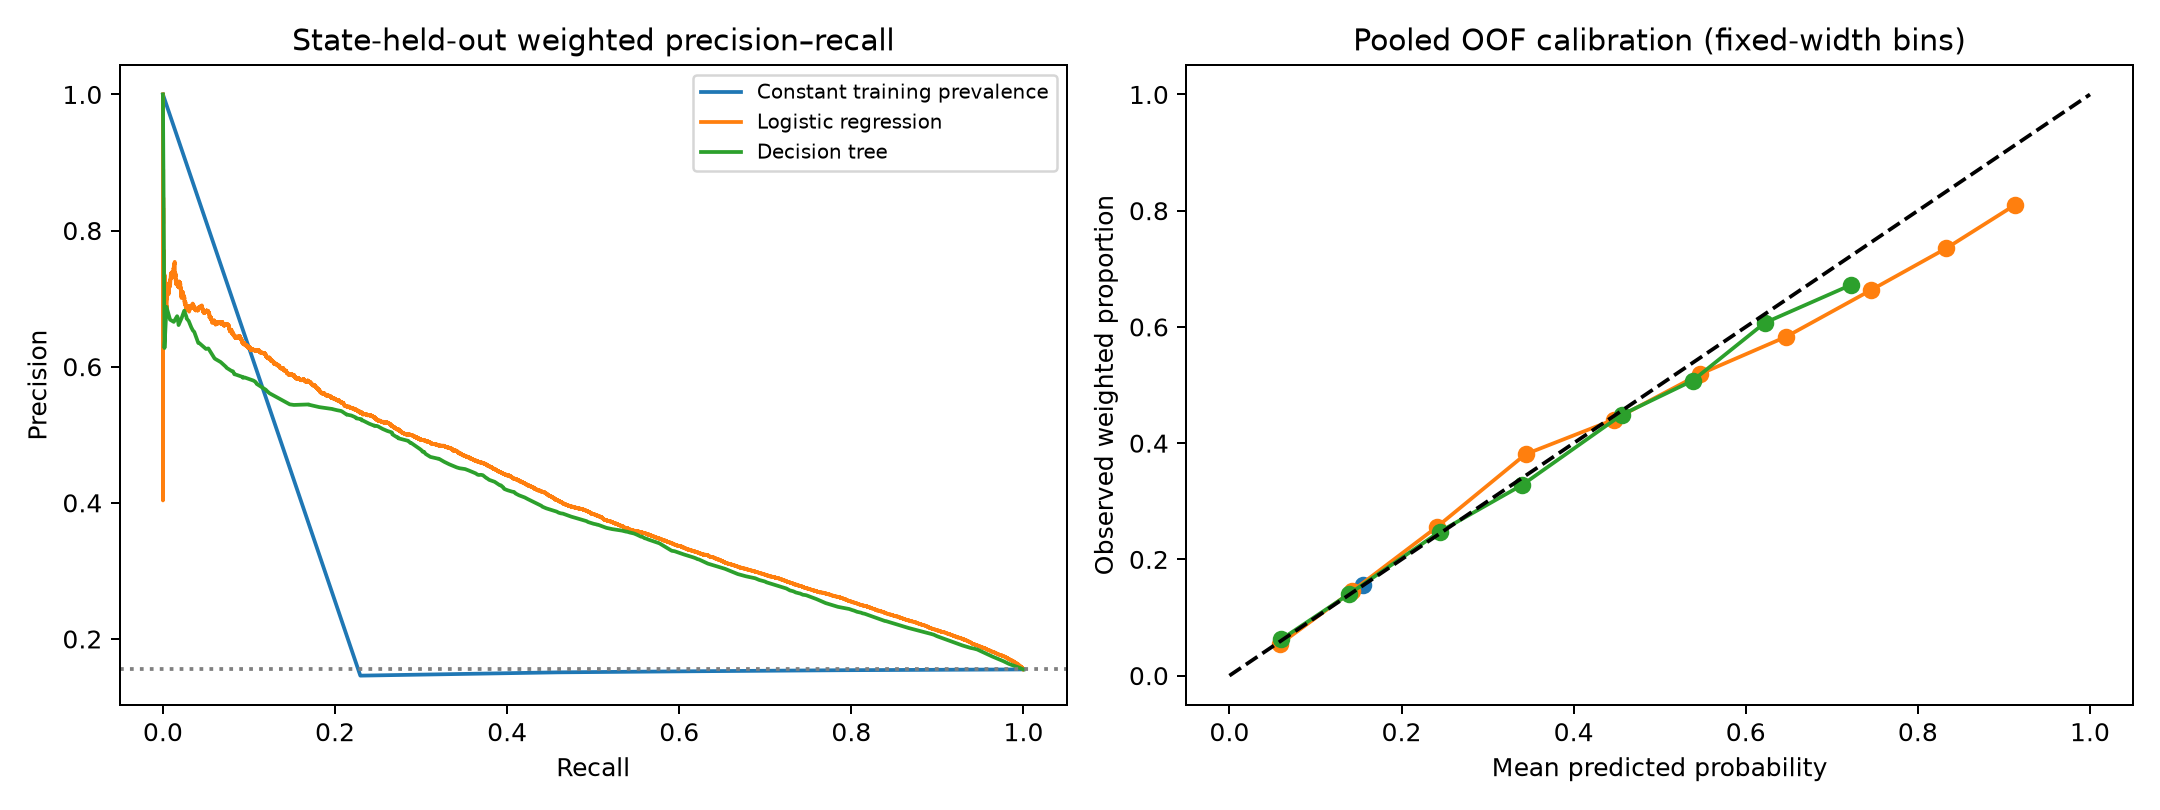

In [29]:
fold_table=result['tables']['fold_metrics']
selected_fold=fold_table.query("Operating_point=='Training-selected sensitivity'")
summary=selected_fold.groupby('Model')[['AP','ROC_AUC','Brier','Sensitivity','Specificity','Precision']].agg(['mean','std'])
display(summary.round(4))
display(result['tables']['pooled_metrics'].round(4))
display(result['tables']['selected_settings'].round(4))
plots(d,result,OUTPUT_DIR)
display(Image(filename=str(OUTPUT_DIR/'precision_recall_calibration.png')))


**Interpretation**
Logistic regression performed best overall in the state-held-out evaluation. Its mean survey-weighted average precision (AP) was **0.4059**, compared with **0.3782** for the decision tree and **0.1558** for the constant baseline. Logistic regression also had a higher mean ROC-AUC (**0.7660**) and a lower Brier score (**0.1126**) than the tree, indicating better discrimination and lower probability prediction error.

The pooled out-of-fold results supported the same conclusion. Logistic regression achieved an AP of **0.4041**, compared with **0.3833** for the tree. Its AP was approximately **2.60 times** the weighted outcome prevalence of **15.52%**. This ratio describes improvement in ranking performance relative to prevalence; it does not mean the model was 2.60 times more accurate. Fold averages and pooled results differ because they summarize predictions differently.

Threshold selection substantially changed how many positive cases were identified. At the default threshold of 0.50, logistic regression detected only **16.38%** of positive cases. Using thresholds selected within training increased pooled sensitivity to **69.96%**. The tree showed a similar increase, from **14.74%** to **70.03%**. Across folds, logistic regression’s mean precision at the selected thresholds was **29.61%**, meaning that roughly three in ten flagged respondents had the outcome. This shows the trade-off between detecting more cases and generating false positives.

The tuning results selected a tree depth of **6** and a minimum leaf size of **200** in every outer fold. Logistic regression’s selected regularization parameter varied across folds. These choices were made within the training data rather than using the held-out states.

The calibration plot suggests that predicted probabilities broadly followed observed proportions, although both models tended to overestimate risk in the higher-probability bins. Bin counts and uncertainty estimates are needed before judging those differences firmly.

Overall, these results favor logistic regression for further analysis. However, the observed performance advantage does not establish statistical significance, clinical usefulness, or readiness for individual screening. The models classify concurrent frequent mental distress rather than predict future illness.

## 7. Does performance transfer across different populations?
The state table pairs the models on the same people. Inspect positive-case counts alongside recall: a small denominator can make a state estimate unstable. Compare AP with prevalence because AP changes with prevalence. AP/prevalence is context, not a complete correction for case-mix differences.

Compare state age distributions, recorded sex, physical health, income missingness, and outcome prevalence with model differences. The additional standardization reweights each state to the pooled age/sex distribution where all cells have at least 20 respondents. It is a descriptive diagnostic, not causal adjustment or proof that population composition caused differences. Population differences can remain in income, morbidity, measurement, and unobserved factors. These diagnostic outputs do not select state-specific thresholds.

,Outer_fold,State_code,Model,Threshold,N,Positive_n,Prevalence,AP,AP_prevalence_ratio,ROC_AUC,Brier,Sensitivity,Specificity,Precision,TN_weighted,FP_weighted,FN_weighted,TP_weighted
0,1,2,Constant training prevalence,0.1582,5393,701,0.1569,0.1569,1.0000,0.5000,0.1323,1.0000,0.0000,0.1569,0.000000e+00,4.660153e+05,0.0000,8.670272e+04
1,1,6,Constant training prevalence,0.1582,8203,1224,0.1485,0.1485,1.0000,0.5000,0.1266,1.0000,0.0000,0.1485,0.000000e+00,2.555015e+07,0.0000,4.456839e+06
2,1,16,Constant training prevalence,0.1582,4268,617,0.1560,0.1560,1.0000,0.5000,0.1317,1.0000,0.0000,0.1560,0.000000e+00,1.291224e+06,0.0000,2.387274e+05
3,1,25,Constant training prevalence,0.1582,9300,1160,0.1332,0.1332,1.0000,0.5000,0.1161,1.0000,0.0000,0.1332,0.000000e+00,4.855225e+06,0.0000,7.461651e+05
4,1,28,Constant training prevalence,0.1582,2934,386,0.1355,0.1355,1.0000,0.5000,0.1176,1.0000,0.0000,0.1355,0.000000e+00,1.939892e+06,0.0000,3.039356e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,5,19,Decision tree,0.1303,8644,1157,0.1488,0.3931,2.6424,0.7649,0.1081,0.7360,0.6601,0.2745,1.398396e+06,7.202074e+05,97752.5619,2.725322e+05
155,5,31,Decision tree,0.1303,12534,1445,0.1345,0.3769,2.8027,0.7689,0.0993,0.7441,0.6579,0.2526,8.585328e+05,4.464269e+05,51882.6490,1.509025e+05
156,5,33,Decision tree,0.1303,6879,713,0.1499,0.4388,2.9272,0.7806,0.1054,0.7042,0.7157,0.3040,7.008074e+05,2.784173e+05,51071.3079,1.215917e+05
157,5,40,Decision tree,0.1303,6834,1146,0.1858,0.4256,2.2908,0.7509,0.1298,0.7464,0.6224,0.3109,1.550621e+06,9.405673e+05,144146.3796,4.242939e+05


,State_code,Tree_minus_logistic_AP,Tree_minus_logistic_Sensitivity,Tree_minus_logistic_Specificity,Tree_minus_logistic_Precision,Tree_minus_logistic_Brier,N,Positive_n,Weighted_prevalence,Age_18_44_fraction,Age_65_plus_fraction,Recorded_female_fraction,Income_missing_fraction,Age_weighted_mean,Body mass index_weighted_mean,Physically unhealthy days_weighted_mean
0,1,-0.0242,-0.0164,-0.0339,-0.0237,0.0015,5034,755,0.1799,0.4469,0.2441,0.5188,0.2004,48.6081,29.2514,4.6753
1,2,-0.0360,0.0089,-0.0300,-0.0159,0.0012,5393,701,0.1569,0.5060,0.1972,0.4720,0.1930,46.3100,28.6888,4.5840
2,4,-0.0022,-0.0030,0.0189,0.0108,-0.0015,8453,1146,0.1420,0.4579,0.2511,0.5044,0.1988,48.5510,28.4066,4.1685
3,5,-0.0410,-0.0351,-0.0013,-0.0110,0.0034,5185,895,0.1991,0.4502,0.2418,0.5125,0.1782,48.4815,29.4559,5.5874
4,6,-0.0259,0.0558,-0.0411,-0.0107,0.0012,8203,1224,0.1485,0.4785,0.2130,0.5054,0.2363,47.2874,27.7435,4.0399
5,8,-0.0217,0.0092,-0.0463,-0.0254,0.0007,10750,1496,0.1516,0.4906,0.2104,0.4949,0.1884,47.0245,27.2517,3.9648
6,9,-0.0298,0.0285,-0.0300,-0.0129,0.0012,7091,990,0.1394,0.4331,0.2444,0.5152,0.2252,48.9910,28.2596,3.9653
7,10,-0.0585,0.0080,-0.0274,-0.0164,0.0054,4293,532,0.1614,0.4146,0.2788,0.5181,0.2287,50.1686,28.9946,4.1232
8,11,-0.0407,0.0326,-0.0548,-0.0249,0.0031,3143,337,0.1328,0.5842,0.1686,0.5390,0.1464,44.1734,27.1507,3.1357
9,12,-0.0441,0.0043,-0.0353,-0.0228,0.0035,12827,1744,0.1564,0.4105,0.2800,0.5115,0.2200,50.4953,28.2013,4.4484


,State_code,Model,Status,N,Positive_n,Prevalence,AP,AP_prevalence_ratio,ROC_AUC,Brier,Sensitivity,Specificity,Precision,TN_weighted,FP_weighted,FN_weighted,TP_weighted
0,1,Logistic regression,Age/sex standardized; descriptive only,5034,755,0.1809,0.4264,2.3568,0.7628,0.1277,0.7607,0.6380,0.3170,2.100433e+06,1.191587e+06,173976.3904,553110.6003
1,1,Decision tree,Age/sex standardized; descriptive only,5034,755,0.1809,0.4020,2.2221,0.7451,0.1292,0.7446,0.6038,0.2933,1.987744e+06,1.304276e+06,185697.7758,541389.2149
2,2,Logistic regression,Age/sex standardized; descriptive only,5393,701,0.1546,0.4285,2.7711,0.7819,0.1096,0.7365,0.6886,0.3019,3.217343e+05,1.455220e+05,22515.9186,62945.7727
3,2,Decision tree,Age/sex standardized; descriptive only,5393,701,0.1546,0.3932,2.5428,0.7683,0.1108,0.7450,0.6619,0.2873,3.092941e+05,1.579622e+05,21793.1446,63668.5467
4,4,Logistic regression,Age/sex standardized; descriptive only,8453,1146,0.1429,0.3540,2.4778,0.7577,0.1088,0.6979,0.6698,0.2606,3.376859e+06,1.664484e+06,253903.9195,586502.4576
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101,66,Decision tree,Age/sex standardized; descriptive only,1635,223,0.1617,0.4077,2.5215,0.7240,0.1212,0.7928,0.5492,0.2533,5.118538e+04,4.201206e+04,3725.5160,14250.7141
102,72,Logistic regression,Age/sex standardized; descriptive only,4277,492,0.1175,0.3325,2.8306,0.7469,0.0954,0.7380,0.5862,0.1918,1.387720e+06,9.794707e+05,82534.4573,232505.1064
103,72,Decision tree,Age/sex standardized; descriptive only,4277,492,0.1175,0.3376,2.8741,0.7584,0.0939,0.7476,0.6245,0.2095,1.478412e+06,8.887790e+05,79527.7498,235511.8140
104,78,Logistic regression,Age/sex standardized; descriptive only,1310,150,0.1309,0.2315,1.7688,0.6160,0.1126,0.5387,0.7164,0.2225,4.267393e+04,1.689021e+04,4138.4638,4832.6428


,Model,Group_type,Group,N,Positive_n,Prevalence,AP,AP_prevalence_ratio,ROC_AUC,Brier,Sensitivity,Specificity,Precision,TN_weighted,FP_weighted,FN_weighted,TP_weighted
0,Constant training prevalence,Recorded sex,Recorded female,235858,37353,0.1788,0.1737,0.9714,0.4868,0.1474,1.0000,0.0000,0.1788,0.000000e+00,1.081872e+08,0.000000e+00,2.354877e+07
1,Constant training prevalence,Recorded sex,Recorded male,213656,24962,0.1308,0.1286,0.9832,0.4935,0.1143,1.0000,0.0000,0.1308,0.000000e+00,1.103892e+08,0.000000e+00,1.661262e+07
2,Constant training prevalence,Age group,65+,169247,14205,0.0873,0.0867,0.9928,0.4965,0.0843,1.0000,0.0000,0.0873,0.000000e+00,5.537388e+07,0.000000e+00,5.296504e+06
3,Constant training prevalence,Age group,45–64,142346,21300,0.1466,0.1421,0.9694,0.4857,0.1252,1.0000,0.0000,0.1466,0.000000e+00,6.818112e+07,0.000000e+00,1.171426e+07
4,Constant training prevalence,Age group,18–44,137921,26810,0.1959,0.1896,0.9677,0.4847,0.1592,1.0000,0.0000,0.1959,0.000000e+00,9.502133e+07,0.000000e+00,2.315063e+07
5,Logistic regression,Recorded sex,Recorded female,235858,37353,0.1788,0.4397,2.4597,0.7644,0.1243,0.7677,0.6154,0.3029,6.657513e+07,4.161202e+07,5.469848e+06,1.807892e+07
6,Logistic regression,Recorded sex,Recorded male,213656,24962,0.1308,0.3494,2.6708,0.7594,0.1000,0.6029,0.7696,0.2825,8.495100e+07,2.543817e+07,6.596281e+06,1.001634e+07
7,Logistic regression,Age group,65+,169247,14205,0.0873,0.2764,3.1665,0.7753,0.0713,0.5011,0.8800,0.2854,4.872907e+07,6.644806e+06,2.642228e+06,2.654276e+06
8,Logistic regression,Age group,45–64,142346,21300,0.1466,0.4216,2.8757,0.7817,0.1048,0.6292,0.8038,0.3553,5.480567e+07,1.337544e+07,4.344073e+06,7.370186e+06
9,Logistic regression,Age group,18–44,137921,26810,0.1959,0.4224,2.1561,0.7215,0.1386,0.7806,0.5051,0.2776,4.799138e+07,4.702994e+07,5.079827e+06,1.807080e+07


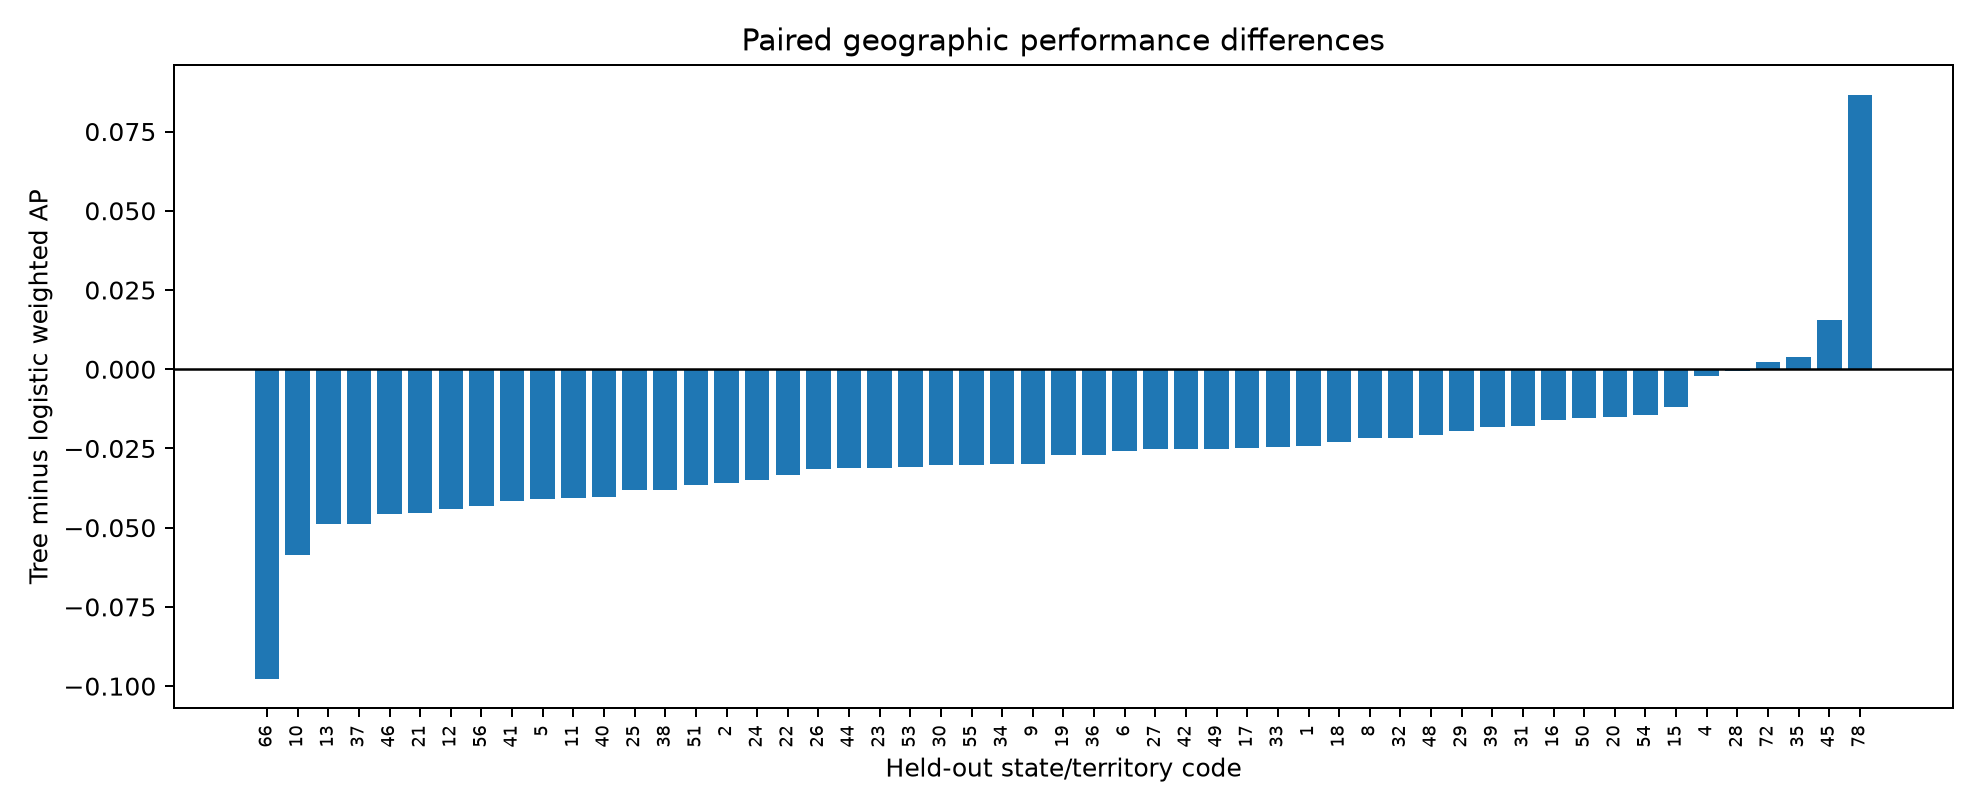

In [30]:
display(result['tables']['state_metrics'].round(4))
display(result['tables']['paired_state_differences'].round(4))
standardized=age_sex_standardization(d,result,OUTPUT_DIR)
display(standardized.round(4))
display(result['tables']['subgroup_metrics'].round(4))
display(Image(filename=str(OUTPUT_DIR/'paired_state_AP.png')))


**Interpretaion**
Logistic regression achieved higher survey-weighted average precision (AP) than the decision tree in **49 of the 53 reporting areas**. The tree performed better in four areas: codes **35, 45, 72, and 78**. The largest tree advantage was **0.0867 AP** in area 78, while the largest logistic-regression advantage was **0.0977 AP** in area 66. This supports logistic regression as the stronger overall model, while showing that its advantage was not consistent everywhere.

Higher AP did not always mean higher sensitivity at the training-selected thresholds. For example, in area 78, the tree had higher AP but sensitivity was **0.0141 lower** than logistic regression. Ranking performance and the number of cases detected therefore need to be considered separately. Area 78 also contained only **150 positive respondents**, so its results should be interpreted cautiously.

The age/sex-standardized analysis compares areas after reweighting them to a common age and recorded-sex distribution. Among the visible results, the tree’s AP advantage in area 78 remained: **0.3343 versus 0.2315** for logistic regression. This suggests that differences in age and sex composition alone did not explain that particular result. However, standardization does not account for every population difference and is descriptive rather than causal.

Logistic regression had higher AP than the tree in every reported sex and age subgroup. However, its sensitivity differed substantially. It identified **76.77%** of positive cases among respondents recorded as female, compared with **60.29%** among those recorded as male. Specificity showed the opposite pattern: **61.54%** and **76.96%**, respectively.

Age differences were also apparent. Logistic-regression sensitivity was **78.06%** among respondents aged 18–44, compared with **50.11%** among those aged 65 or older. Specificity was **50.51%** in the younger group and **88.00%** in the older group. Thus, the selected thresholds detected more positive cases among younger respondents but also flagged more respondents without the outcome.

These findings show that an overall sensitivity near 70% does not guarantee similar performance across groups. Differences in outcome prevalence also affect AP and precision, so these metrics alone cannot establish fairness. Geographic and subgroup comparisons remain descriptive without appropriate uncertainty estimates.

## 8. Complexity and learned-rule stability
A high training score followed by worse held-out AP, especially for deeper/smaller-leaf trees, is evidence consistent with overfitting. Compare candidate training/inner-validation gaps and selected-model training/outer gaps. A gap can also reflect population shift; it does not identify the cause alone.

Refit stability checks retain 80% of the outer training states across five fixed seeds while keeping settings, the held-out states, and the threshold fixed. Both models are refitted. Prediction disagreement and absolute probability changes are weighted on the same held-out people. Root-feature changes and split-feature overlap provide further tree diagnostics. This separates rule sensitivity from changes in the evaluation population. It is not a survey bootstrap, a confidence interval, or an independent validation study. Root cutoffs are in transformed units and must not be compared as raw age or health-day cutoffs.

In [31]:
display(result['tables']['inner_complexity_comparison'].round(4))
display(result['tables']['training_heldout_gaps'].round(4))
display(result['tables']['model_complexity'].round(4))
if RUN_STABILITY:
    refit_metrics,rule_stability=stability_checks(d,result,OUTPUT_DIR)
    display(refit_metrics.round(4),rule_stability.round(4))
else:
    print('Refit stability not executed; do not claim stable rules.')


,Outer_fold,Model,Parameters,Mean_inner_AP,Mean_inner_training_AP,Inner_training_validation_AP_gap
0,1,Logistic regression,"{""C"": 0.1}",0.4119,0.4136,0.0017
1,1,Logistic regression,"{""C"": 1}",0.4119,0.4136,0.0017
2,1,Logistic regression,"{""C"": 10}",0.4118,0.4136,0.0018
3,1,Decision tree,"{""max_depth"": 3, ""min_samples_leaf"": 200}",0.3305,0.3335,0.0030
4,1,Decision tree,"{""max_depth"": 3, ""min_samples_leaf"": 50}",0.3305,0.3335,0.0030
5,1,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 200}",0.3849,0.4005,0.0156
6,1,Decision tree,"{""max_depth"": 6, ""min_samples_leaf"": 50}",0.3820,0.4023,0.0203
7,2,Logistic regression,"{""C"": 0.1}",0.4039,0.4060,0.0021
8,2,Logistic regression,"{""C"": 1}",0.4038,0.4060,0.0022
9,2,Logistic regression,"{""C"": 10}",0.4038,0.4061,0.0023


,Outer_fold,Model,Apparent_training_AP,Heldout_AP,AP_gap
0,1,Logistic regression,0.4137,0.3791,0.0346
1,1,Decision tree,0.3980,0.3523,0.0457
2,2,Logistic regression,0.4053,0.4103,-0.0050
3,2,Decision tree,0.3910,0.3855,0.0054
4,3,Logistic regression,0.4068,0.4030,0.0038
5,3,Decision tree,0.3896,0.3814,0.0082
6,4,Logistic regression,0.4047,0.4136,-0.0089
7,4,Decision tree,0.3909,0.3801,0.0107
8,5,Logistic regression,0.4015,0.4234,-0.0219
9,5,Decision tree,0.3877,0.3915,-0.0039


,Outer_fold,Model,Encoded_predictors_n,C,Coefficient_L2_norm,Depth,Leaves,Nodes
0,1,Logistic regression,43,0.1,1.7940,NaN,NaN,NaN
1,1,Decision tree,43,NaN,NaN,6.0,61.0,121.0
2,2,Logistic regression,43,0.1,1.8389,NaN,NaN,NaN
3,2,Decision tree,43,NaN,NaN,6.0,61.0,121.0
4,3,Logistic regression,43,1.0,1.8588,NaN,NaN,NaN
5,3,Decision tree,43,NaN,NaN,6.0,62.0,123.0
6,4,Logistic regression,43,10.0,1.9349,NaN,NaN,NaN
7,4,Decision tree,43,NaN,NaN,6.0,61.0,121.0
8,5,Logistic regression,43,1.0,1.8120,NaN,NaN,NaN
9,5,Decision tree,43,NaN,NaN,6.0,61.0,121.0


,Outer_fold,Refit_seed,Model,Training_states_n,Weighted_prediction_disagreement,Weighted_absolute_probability_change,N,Positive_n,Prevalence,AP,AP_prevalence_ratio,ROC_AUC,Brier,Sensitivity,Specificity,Precision,TN_weighted,FP_weighted,FN_weighted,TP_weighted
0,1,0,Logistic regression,35,0.0085,0.0028,90271,12321,0.1461,0.3788,2.5927,0.7519,0.1089,0.6431,0.7211,0.2829,3.882712e+07,1.501849e+07,3.287750e+06,5.924339e+06
1,1,0,Decision tree,35,0.0272,0.0172,90271,12321,0.1461,0.3494,2.3918,0.7409,0.1105,0.6927,0.6703,0.2644,3.609004e+07,1.775558e+07,2.831147e+06,6.380942e+06
2,1,7,Logistic regression,35,0.0142,0.0036,90271,12321,0.1461,0.3785,2.5909,0.7508,0.1089,0.6421,0.7206,0.2822,3.880077e+07,1.504484e+07,3.297314e+06,5.914774e+06
3,1,7,Decision tree,35,0.0880,0.0326,90271,12321,0.1461,0.3491,2.3894,0.7392,0.1103,0.6733,0.6778,0.2634,3.649539e+07,1.735022e+07,3.009145e+06,6.202944e+06
4,1,21,Logistic regression,35,0.0141,0.0036,90271,12321,0.1461,0.3796,2.5987,0.7527,0.1088,0.6355,0.7330,0.2894,3.947046e+07,1.437515e+07,3.357405e+06,5.854684e+06
5,1,21,Decision tree,35,0.0336,0.0203,90271,12321,0.1461,0.3482,2.3832,0.7395,0.1106,0.6898,0.6650,0.2605,3.580776e+07,1.803785e+07,2.857142e+06,6.354946e+06
6,1,42,Logistic regression,35,0.0136,0.0040,90271,12321,0.1461,0.3781,2.5885,0.7512,0.1088,0.6469,0.7181,0.2819,3.866635e+07,1.517926e+07,3.252820e+06,5.959269e+06
7,1,42,Decision tree,35,0.0540,0.0225,90271,12321,0.1461,0.3504,2.3987,0.7403,0.1101,0.6865,0.6749,0.2654,3.633860e+07,1.750701e+07,2.888096e+06,6.323993e+06
8,1,99,Logistic regression,35,0.0061,0.0019,90271,12321,0.1461,0.3795,2.5979,0.7519,0.1088,0.6408,0.7220,0.2828,3.887618e+07,1.496943e+07,3.309225e+06,5.902864e+06
9,1,99,Decision tree,35,0.0133,0.0084,90271,12321,0.1461,0.3517,2.4078,0.7392,0.1103,0.6684,0.6907,0.2699,3.718978e+07,1.665583e+07,3.054554e+06,6.157535e+06


,Outer_fold,Refit_seed,Root_feature,Root_threshold_transformed_units,Split_feature_Jaccard,Depth,Leaves
0,1,0,numeric__PHYSHLTH,0.5634,0.5909,6,59
1,1,7,numeric__PHYSHLTH,0.5660,0.4800,6,60
2,1,21,numeric__PHYSHLTH,0.5751,0.5217,6,59
3,1,42,numeric__PHYSHLTH,0.2245,0.6190,6,61
4,1,99,numeric__PHYSHLTH,0.2155,0.7500,6,62
5,2,0,numeric__PHYSHLTH,0.2321,0.7619,6,62
6,2,7,numeric__PHYSHLTH,0.2282,0.5769,6,60
7,2,21,numeric__PHYSHLTH,0.2338,0.5909,6,60
8,2,42,numeric__PHYSHLTH,0.2264,0.8095,6,61
9,2,99,numeric__PHYSHLTH,0.2310,0.5833,6,59


**Interpretation**
The selected decision trees had a maximum depth of **6**, with **61–62 leaves** across the five outer folds. Both models received 43 encoded predictor columns, created from the eleven original predictors.

Increasing tree depth from 3 to 6 improved inner-validation average precision (AP). However, reducing the minimum leaf size from 200 to 50 increased training performance while slightly reducing validation performance in every fold. The smaller-leaf trees also had larger training–validation gaps. This pattern is consistent with overfitting and supports selecting the minimum leaf size of **200**. Logistic regression’s validation AP changed very little across the three regularization settings.

The training-to-held-out gaps varied geographically. Both models had their largest performance drop in outer fold 1: **0.0346 AP** for logistic regression and **0.0457 AP** for the tree. Some other folds had higher held-out than training AP. These differences may reflect population differences between states as well as overfitting; the gaps alone cannot separate these explanations.

The refit checks showed that logistic regression’s predictions were more stable when the training-state composition changed. Across 25 refits using 80% of the available training states, its weighted prediction disagreement with the original model ranged from **0.61% to 2.07%**. For the tree, disagreement ranged from **1.33% to 15.15%**. Average absolute probability changes were also smaller for logistic regression.

Physically unhealthy days remained the tree’s first splitting variable in all 25 refits. However, the overlap between the sets of splitting features ranged from approximately **0.45 to 0.81** on the Jaccard scale, where 1 indicates identical sets. This shows that a consistent first variable did not guarantee stable rules throughout the tree. The reported root thresholds are in standardized units and should not be interpreted directly as numbers of unhealthy days.

Overall, these checks favor logistic regression because it combined stronger held-out AP with more stable predictions. The refit exercise assesses sensitivity to training-state composition; it does not provide confidence intervals or establish statistical significance.

## 9. Survey-weighted prediction versus design-based inference
Weights affect fitting and predictive scores. They do **not** automatically produce correct standard errors. CDC specifies the final survey weight, sampling strata, and primary sampling units for complex-sample analysis. The following ratios use a with-replacement Taylor approximation: weighted residuals are summed within each sampling unit, and their variation is calculated within each state/stratum. All design-valid records remain represented, including zero-contribution records outside the eligible outcome domain.

For prevalence, this is a design-based domain calculation subject to the approximation and response limitations. For predictive metrics, the out-of-fold probabilities/decisions are treated as fixed: these are **conditional descriptive intervals**, omitting variability from fitting, tuning, and choosing thresholds. They are not complete uncertainty intervals for the learning procedure. AP, ROC-AUC, and calibration receive no design-based interval here. Full learning-procedure uncertainty remains final-paper work requiring a documented survey resampling design that repeats fitting and selection. Ordinary row bootstrapping, fold SDs, and state-subsampling stability are not substitutes.

The function withholds intervals if eligible respondents lack design identifiers or if a single-unit stratum occurs, rather than inventing a correction. No finite-population correction is assumed; weights and design identifiers are held fixed. These approximations do not repair nonresponse bias. Diagnostic subsamples skip this inference entirely.

In [32]:
if DIAGNOSTIC_N is None:
    conditional_intervals=uncertainty_tables(raw,d,result,OUTPUT_DIR)
    display(conditional_intervals.round(4))
else:
    display(design_audit(raw))
    print('Survey-design intervals skipped for diagnostic subsample.')


,Quantity,Scope,Estimate,SE,Status
0,Eligible-domain distress prevalence,Survey-design prevalence; complete-case outcom...,0.1552,NaN,Single-PSU stratum; CI withheld pending docume...
1,Constant training prevalence Brier,Conditional on fixed out-of-fold scores; exclu...,0.1311,NaN,Single-PSU stratum; CI withheld pending docume...
2,Constant training prevalence Sensitivity,Conditional on fixed out-of-fold scores; exclu...,1.0000,NaN,Single-PSU stratum; CI withheld pending docume...
3,Constant training prevalence Specificity,Conditional on fixed out-of-fold scores; exclu...,0.0000,NaN,Single-PSU stratum; CI withheld pending docume...
4,Logistic regression Brier,Conditional on fixed out-of-fold scores; exclu...,0.1124,NaN,Single-PSU stratum; CI withheld pending docume...
5,Logistic regression Sensitivity,Conditional on fixed out-of-fold scores; exclu...,0.6996,NaN,Single-PSU stratum; CI withheld pending docume...
6,Logistic regression Specificity,Conditional on fixed out-of-fold scores; exclu...,0.6932,NaN,Single-PSU stratum; CI withheld pending docume...
7,Decision tree Brier,Conditional on fixed out-of-fold scores; exclu...,0.1138,NaN,Single-PSU stratum; CI withheld pending docume...
8,Decision tree Sensitivity,Conditional on fixed out-of-fold scores; exclu...,0.7003,NaN,Single-PSU stratum; CI withheld pending docume...
9,Decision tree Specificity,Conditional on fixed out-of-fold scores; exclu...,0.6750,NaN,Single-PSU stratum; CI withheld pending docume...


Standard errors and confidence intervals were withheld because 110 sampling strata contained only one sampling unit and no handling method was specified. The estimates are reported descriptively, without claims of statistical significance.

## 10. Prespecified sensitivity analyses
Each analysis below repeats nested selection on the same respondents and outer states. One removes physically unhealthy days, which shares the outcome's 30-day recall window. The other omits fitting weights but retains survey-weighted evaluation. Comparing these with the main analysis examines dependence on a concurrent health measure and on weighted training. If skipped, report them as remaining work.

In [33]:
RUN_SENSITIVITIES = True

print("Running analysis without physically unhealthy days...")
no_physical = nested_comparison(
    d,
    OUTPUT_DIR / "without_physical_health",
    features=[c for c in FEATURES if c != "PHYSHLTH"]
)

print("Running analysis without model-fitting weights...")
unweighted = nested_comparison(
    d,
    OUTPUT_DIR / "unweighted_fitting",
    weighted_fit=False
)

for title, r in [
    ("No physical-health days", no_physical),
    ("Unweighted fitting", unweighted)
]:
    print(title)

Running analysis without physically unhealthy days...
Outer fold 1/5: tuning Logistic regression
Outer fold 1/5: tuning Decision tree
Outer fold 2/5: tuning Logistic regression
Outer fold 2/5: tuning Decision tree
Outer fold 3/5: tuning Logistic regression
Outer fold 3/5: tuning Decision tree
Outer fold 4/5: tuning Logistic regression
Outer fold 4/5: tuning Decision tree
Outer fold 5/5: tuning Logistic regression
Outer fold 5/5: tuning Decision tree
Running analysis without model-fitting weights...
Outer fold 1/5: tuning Logistic regression
Outer fold 1/5: tuning Decision tree
Outer fold 2/5: tuning Logistic regression
Outer fold 2/5: tuning Decision tree
Outer fold 3/5: tuning Logistic regression
Outer fold 3/5: tuning Decision tree
Outer fold 4/5: tuning Logistic regression
Outer fold 4/5: tuning Decision tree
Outer fold 5/5: tuning Logistic regression
Outer fold 5/5: tuning Decision tree
No physical-health days
Unweighted fitting


In [34]:
for title, r in [
    ("Main analysis", result),
    ("Without physically unhealthy days", no_physical),
    ("Without model-fitting weights", unweighted)
]:
    print(title)
    display(
        r["tables"]["pooled_metrics"]
        .query("Operating_point == 'Training-selected sensitivity'")
        [["Model", "AP", "ROC_AUC", "Brier",
          "Sensitivity", "Specificity", "Precision"]]
        .round(4)
    )

Main analysis


,Model,AP,ROC_AUC,Brier,Sensitivity,Specificity,Precision
1,Constant training prevalence,0.1515,0.4896,0.1311,1.0000,0.0000,0.1552
3,Logistic regression,0.4041,0.7654,0.1124,0.6996,0.6932,0.2953
5,Decision tree,0.3833,0.7519,0.1138,0.7003,0.6750,0.2836


Without physically unhealthy days


,Model,AP,ROC_AUC,Brier,Sensitivity,Specificity,Precision
1,Constant training prevalence,0.1515,0.4896,0.1311,1.0000,0.0000,0.1552
3,Logistic regression,0.3355,0.7186,0.1191,0.7005,0.6166,0.2513
5,Decision tree,0.3071,0.6996,0.1212,0.7206,0.5594,0.2310


Without model-fitting weights


,Model,AP,ROC_AUC,Brier,Sensitivity,Specificity,Precision
1,Constant training prevalence,0.1515,0.4896,0.1311,1.0000,0.0000,0.1552
3,Logistic regression,0.4035,0.7644,0.1124,0.6999,0.6878,0.2918
5,Decision tree,0.3856,0.7555,0.1133,0.7199,0.6574,0.2785


**Interpretation**
Removing physically unhealthy days reduced performance for both models. Logistic regression’s average precision (AP) decreased from **0.4041 to 0.3355**, while the decision tree’s AP decreased from **0.3833 to 0.3071**. ROC-AUC also decreased, and Brier scores increased, indicating poorer discrimination and greater probability prediction error.

Sensitivity remained near 70% because thresholds were selected within training to target that level. However, specificity and precision decreased. For logistic regression, specificity fell from **69.32% to 61.66%**, and precision fell from **29.53% to 25.13%**. The models therefore detected a similar proportion of positive cases while flagging more respondents without the outcome. These findings show that physically unhealthy days contributed useful information, although they do not establish a causal relationship. Both models still outperformed the constant baseline after this predictor was removed.

Removing survey weights from model fitting produced much smaller changes when evaluation remained survey-weighted. Logistic regression’s AP changed from **0.4041 to 0.4035**, while the tree’s AP increased slightly from **0.3833 to 0.3856**. The unweighted-fitting tree had higher sensitivity (**71.99% versus 70.03%**), but lower specificity and precision. This represents a trade-off rather than a clear improvement.

Logistic regression retained higher AP, higher ROC-AUC, and a lower Brier score than the tree in both sensitivity analyses. Its overall advantage therefore persisted under these two checks. However, absolute performance depended noticeably on including physically unhealthy days. These results support the model preference under the conditions examined, without establishing statistical significance or robustness to every possible analysis choice.

## 11. Save the reproducibility record and interpret the evidence
Only aggregate tables and figures are saved. Model-level probabilities and respondent records stay in notebook memory. Do not display or upload row-level data. Review aggregate summaries for small-cell concerns before sharing them. The manifest omits your absolute local path. Keep the XPT, local output directory, and any prediction files excluded through `.gitignore`. The README should state that Milestone 2 code is implemented and whether real-data execution is complete.

In [35]:
manifest={'Input_SHA256':input_sha256,'Input_shape':list(raw.shape),'Eligible_full_n':full_eligible_n,
    'Modeling_n':len(d),'Diagnostic_subsample':DIAGNOSTIC_N is not None,
    'Weighted_prevalence':float(np.average(d.target,weights=d._LLCPWT)),
    'Unweighted_prevalence':float(d.target.mean()),'Seed':42,'Outer_folds':5,'Inner_folds':3,
    'Software':{'Python':platform.python_version(),'NumPy':np.__version__,'pandas':pd.__version__,
        'scikit-learn':sklearn.__version__,'SciPy':scipy.__version__},
    'Grids':GRIDS,'Predictors':FEATURES,'Refit_stability_executed':RUN_STABILITY,
    'Sensitivity_analyses_executed':RUN_SENSITIVITIES,
    'Uncertainty':'Conditional fixed-OOF Taylor ratios; excludes fitting/tuning uncertainty; no AP CI',
    'Respondent_exports':'None'}
(OUTPUT_DIR/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2))
main=selected_fold.groupby('Model')[['AP','Brier','Sensitivity','Specificity','Precision']].mean()
display(main.round(4))
delta=main.loc['Decision tree','AP']-main.loc['Logistic regression','AP']
print(f'Mean-fold weighted AP difference, tree minus logistic: {delta:+.4f}')
print('Use paired state results, calibration, thresholds, and stability before making the final recommendation.')


,AP,Brier,Sensitivity,Specificity,Precision
Model,,,,,
Constant training prevalence,0.1558,0.1316,1.0000,0.0000,0.1558
Decision tree,0.3782,0.1141,0.7019,0.6746,0.2848
Logistic regression,0.4059,0.1126,0.7014,0.6921,0.2961


Mean-fold weighted AP difference, tree minus logistic: -0.0277
Use paired state results, calibration, thresholds, and stability before making the final recommendation.


**Conclusion and Model Recommendation**
I would retain logistic regression as the preferred model for further investigation. Its mean survey-weighted average precision (AP) was **0.4059**, compared with **0.3782** for the decision tree. The tree-minus-logistic difference of **−0.0277** therefore favors logistic regression.

Both models achieved approximately **70% sensitivity**, but logistic regression had higher specificity (**69.21% versus 67.46%**) and precision (**29.61% versus 28.48%**). It identified a similar proportion of positive cases while producing fewer false positives. Its lower Brier score (**0.1126 versus 0.1141**) also indicated lower probability prediction error.

The other analyses supported this preference. Logistic regression had higher AP in **49 of 53 reporting areas**, showed more stable predictions during training-state refits, and retained its overall performance advantage in both sensitivity analyses. However, removing physically unhealthy days reduced performance substantially for both models.

These findings support logistic regression for this research comparison, but they do not establish statistical significance or readiness for individual screening. Survey-design confidence intervals remain unavailable, and performance differed across geographic areas and demographic groups. The models classify concurrent frequent mental distress rather than predict future illness.


## Source
- CDC. (2025). *Complex sampling weights and preparing 2024 BRFSS module data for analysis*. https://www.cdc.gov/brfss/annual_data/2024/pdf/Complex-Sampling-Weights-and-Preparing-Module-Data-for-Analysis-2024-508.pdf

